In [1]:
import matplotlib.pyplot as plt
import numpy as np
# 1. Data Sampel
# x: Luas tanah (m2)
# y: Harga tanah (juta Rp)
x = np.array([60, 72, 90, 120, 150, 200, 250, 300], dtype=float)
y = np.array([302, 385, 480, 620, 789, 1025, 1250, 1510], dtype=float)
# 2. Menghitung Parameter Regresi (w dan b) secara Manual
# Formula OLS:
# w = sum((x- mean_x) * (y- mean_y)) / sum((x- mean_x)^2)
# b = mean_y- (w * mean_x)
x_mean = np.mean(x)
y_mean = np.mean(y)

In [37]:
# Menghitung bobot (weight/slope) dan bias (intercept)
numerator = np.sum((x- x_mean) * (y- y_mean))
denominator = np.sum((x- x_mean) ** 2)
w = numerator / denominator
b = y_mean- (w * x_mean)

print(f"Persamaan Regresi: Harga = {w:.2f} * Luas + {b:.2f}")

Persamaan Regresi: Harga = 4.95 * Luas + 26.35


In [38]:
# 3. Menghitung Prediksi untuk Data Asli (Garis Regresi)
y_pred = w * x + b
# 4. Contoh Uji Prediksi Data Baru (misal luas tanah = 180 m²)
luas_baru = 130
harga_prediksi = w * luas_baru + b
print(f"Estimasi harga tanah luas {luas_baru} m²: Rp {harga_prediksi:.2f} juta")

Estimasi harga tanah luas 130 m²: Rp 670.09 juta


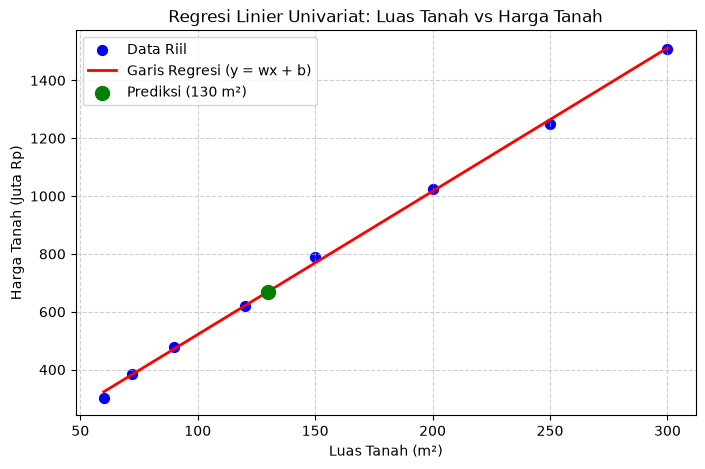

In [40]:
# 5. Plot Visualisasi
plt.figure(figsize=(8, 5))

# Plot titik data asli
plt.scatter(x, y, color="blue", label="Data Riil", s=50)

# Plot garis regresi
plt.plot(x, y_pred, color="red", linewidth=2, label="Garis Regresi (y = wx + b)")
# Plot titik prediksi baru
plt.scatter(
[luas_baru],
[harga_prediksi],
color="green",
s=100,
zorder=5,
label=f"Prediksi ({luas_baru} m²)",
)
plt.title("Regresi Linier Univariat: Luas Tanah vs Harga Tanah")
plt.xlabel("Luas Tanah (m²)")
plt.ylabel("Harga Tanah (Juta Rp)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

Plot generated successfully


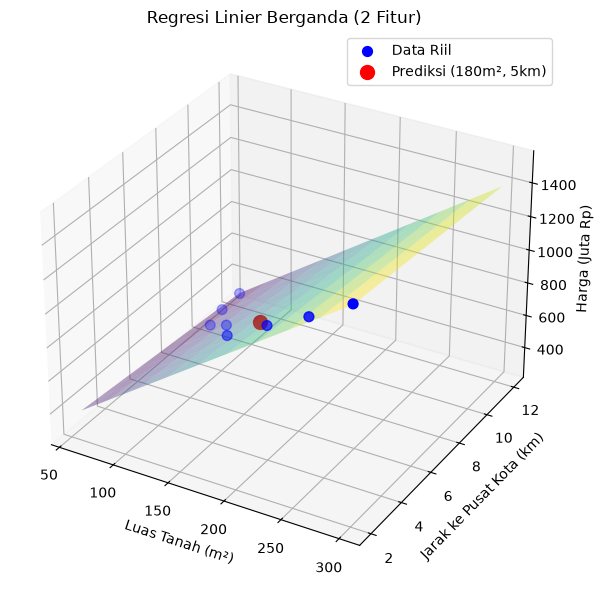

In [7]:
#Program regresi multivariat dengan numpy
import numpy as np
import matplotlib.pyplot as plt
# Data
x1 = np.array([60, 72, 90, 120, 150, 200, 250, 300], dtype=float)
x2 = np.array([12, 10, 8, 7, 5, 4, 3, 2], dtype=float)
y = np.array([300, 380, 480, 620, 780, 1020, 1250, 1500], dtype=float)

# Matrix X dengan bias (kolom 1)
X = np.column_stack((np.ones(len(x1)), x1, x2))
beta = np.linalg.inv(X.T @ X) @ X.T @ y
b, w1, w2 = beta

# Grid untuk bidang regresi
x1_range = np.linspace(min(x1), max(x1), 10)
x2_range = np.linspace(min(x2), max(x2), 10)
X1_grid, X2_grid = np.meshgrid(x1_range, x2_range)
Y_grid = b + w1 * X1_grid + w2 * X2_grid

# Plot 3D
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')

# Scatter data asli
ax.scatter(x1, x2, y, color='blue', s=50, label='Data Riil')

# Plot bidang regresi
ax.plot_surface(X1_grid, X2_grid, Y_grid, alpha=0.4, cmap='viridis')

# Prediksi titik baru
luas_baru, jarak_baru = 180, 5
harga_prediksi = b + w1 * luas_baru + w2 * jarak_baru
ax.scatter([luas_baru], [jarak_baru], [harga_prediksi], color='red', s=100,
label=f'Prediksi ({luas_baru}m², {jarak_baru}km)')
ax.set_xlabel('Luas Tanah (m²)')
ax.set_ylabel('Jarak ke Pusat Kota (km)')
ax.set_zlabel('Harga (Juta Rp)')
ax.set_title('Regresi Linier Berganda (2 Fitur)')
ax.legend()
plt.tight_layout()
plt.savefig('regression_3d.png')
print("Plot generated successfully")

In [ ]:
#Program Regresi dengan scikit-learn

In [2]:
 # %load linReg.py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

# unduh dan siapkan data
sumber_data="https://github.com/ageron/data/raw/main/"
lifesat=pd.read_csv(sumber_data + "lifesat/lifesat.csv")
x=lifesat[["GDP per capita (USD)"]].values
y=lifesat[["Life satisfaction"]].values

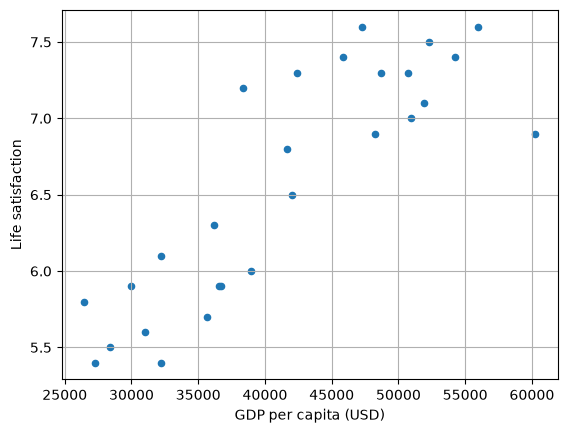

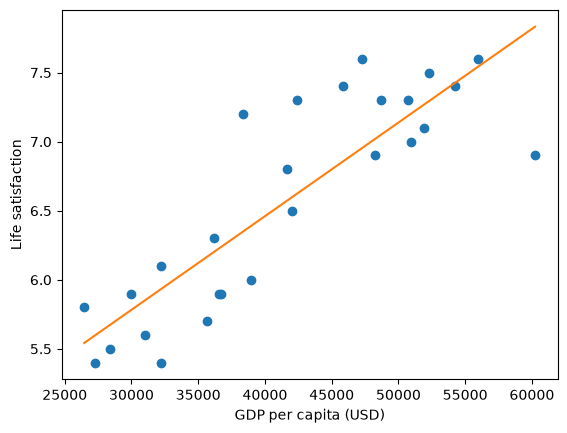

In [31]:
# visualiasiskan data
lifesat.plot(kind='scatter',grid=True,x="GDP per capita (USD)",y="Life satisfaction")
plt.show()
model=LinearRegression()
model.fit(x,y)
x_baru=x#[[33442.8]]
y_baru=model.predict(x_baru)
plt.plot(x,y,'o',x_baru,y_baru)
plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life satisfaction")
plt.show()